# Start

In [89]:
from pyprojroot import here
import polars as pl
import cv2
import numpy as np
from typing import Literal
import matplotlib.pyplot as plt
import seaborn as sns
import os
from skimage.filters import frangi

In [90]:
# params
path_data = here() / "data"
path_processed = path_data / "processed"
path_raw = path_data / "raw"
path_raw_img = path_raw / "Images"
path_sample_img = path_raw_img / "31_2.jpg"
path_crop_out = path_processed / "od_images"

size_preview = (500, 500)

seed = 123

In [91]:
df = pl.read_csv(path_processed / "labels.csv")
df.head()

Image Name,Patient,Label,Quality Score,SPLIT,Height,Width
str,i64,str,f64,str,i64,i64
"""0_0.jpg""",0,"""GON+""",6.18,"""TRAIN""",1918,1918
"""1_0.jpg""",1,"""GON+""",5.31,"""TRAIN""",1929,1929
"""1_1.jpg""",1,"""GON+""",4.37,"""TRAIN""",1940,1940
"""2_0.jpg""",2,"""GON+""",3.51,"""TRAIN""",1893,1893
"""2_1.jpg""",2,"""GON+""",4.24,"""TRAIN""",1900,1900


# Tools

In [92]:
def imshow(input) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    cv2.imshow("Preview window", _img_resize)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [93]:
def imshow_c(input, channel: Literal["B", "G", "R"]) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    _img_channel = _img_resize[:, :, {"B": 0, "G": 1, "R": 2}[channel]]
    cv2.imshow("Preview window", _img_channel)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [94]:
def imshow_2(in1:np.ndarray, in2:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [95]:
def imshow_3(in1:np.ndarray, in2:np.ndarray, in3:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _in3_resize = cv2.resize(in3, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize, _in3_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [96]:
def mark(img, max_loc, crop_ratio=0.3):
    out = img.copy()
    h, w = out.shape[:2]

    crop_w = int(w * crop_ratio)
    crop_h = int(h * crop_ratio)

    x1 = max(max_loc[0] - crop_w // 2, 0)
    y1 = max(max_loc[1] - crop_h // 2, 0)
    x2 = min(max_loc[0] + crop_w // 2, w)
    y2 = min(max_loc[1] + crop_h // 2, h)

    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 10)
    cv2.drawMarker(out, max_loc, (0, 0, 255), cv2.MARKER_CROSS, 100, 15)

    return out

In [97]:
def shade_fov_region(img, mask, alpha=0.4, color=(0, 255, 0)):
    """
    Shades the 'ignored' regions of an image based on a binary mask.

    Args:
        img: Original BGR image.
        mask: Binary mask (uint8, same size as img). 255 = keep, 0 = shade.
        alpha: Transparency of the shade (0.0 to 1.0).
        color: BGR color for the shade
    """
    overlay = img.copy()

    if len(mask.shape) == 3:
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
    overlay[mask == 0] = color
    output = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)

    return output

In [98]:
def crop_od(img, max_loc, crop_ratio=0.3):
    img_ori = img.copy()

    crop_resize = 512
    sample_height = img_ori.shape[0]
    sample_width = img_ori.shape[1]

    # cropping
    crop_width = int(sample_width * crop_ratio)
    crop_height = int(sample_height * crop_ratio)

    x1 = max(max_loc[0] - crop_width // 2, 0)
    y1 = max(max_loc[1] - crop_height // 2, 0)
    x2 = min(max_loc[0] + crop_width // 2, sample_width)
    y2 = min(max_loc[1] + crop_height // 2, sample_height)

    cropped_img = img_ori[y1:y2, x1:x2]
    cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))

    return cropped_resize_img

# OD - Mask ensemble

In [99]:
# Params
crop_ratio = 0.3
crop_resize = 512

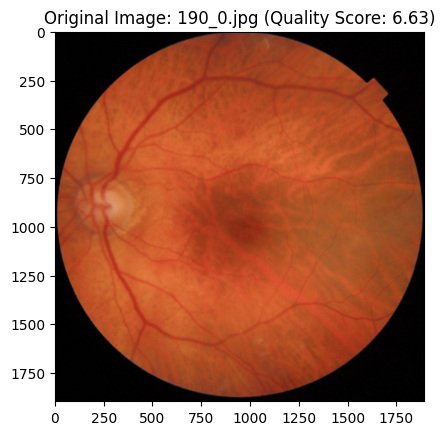

In [100]:
# img_file_name = None

# img_file_name = "31_2"  # random white spot + halo
img_file_name = "190_0"

# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

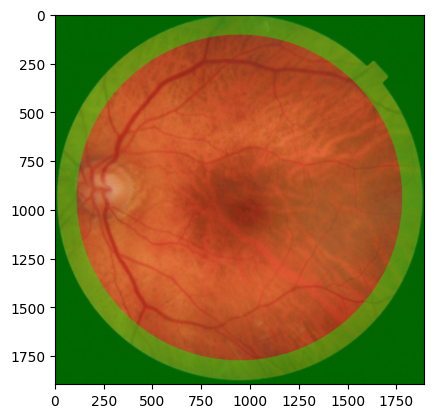

In [101]:
# get fov mask
def get_fov_mask(img_ori):
    h, w = img_ori.shape[:2]
    green = img_ori[:, :, 1]
    blurred_fov = cv2.medianBlur(green, 31)
    circles = cv2.HoughCircles(
        blurred_fov,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=1000,
        param1=50,
        param2=30,
        minRadius=int(h * 0.3),
        maxRadius=int(h * 0.6),
    )
    fov_mask = np.zeros_like(green)
    if circles is not None:
        circles = np.uint16(np.around(circles))
        i = circles[0, 0]
        cv2.circle(fov_mask, (i[0], i[1]), i[2], 255, -1)
    else:
        _, fov_mask = cv2.threshold(blurred_fov, 10, 255, cv2.THRESH_BINARY)
    kernel_erode = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (201, 201))
    halo_sieve = cv2.erode(fov_mask, kernel_erode, iterations=1)
    sieve_f = halo_sieve.astype(np.float32) / 255.0

    return sieve_f


fov_mask = get_fov_mask(img_ori)
plt.imshow(cv2.cvtColor(shade_fov_region(img_ori, fov_mask), cv2.COLOR_BGR2RGB))

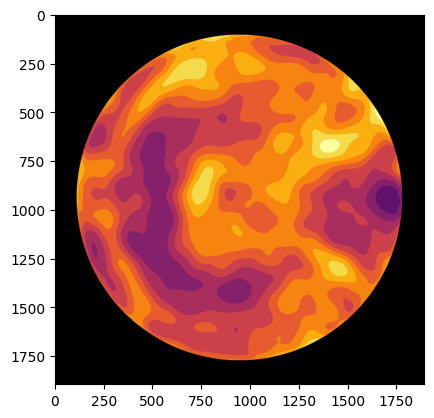

In [102]:
def get_texture_map(img_ori):
    h, w = img_ori.shape[:2]
    red = img_ori[:, :, 2]
    red = cv2.medianBlur(red, 15)
    grad_red = cv2.morphologyEx(
        red, cv2.MORPH_GRADIENT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    )
    blur_tex = int(w * 0.15) | 1  # 15% image width hotspot
    tex_hub = cv2.normalize(
        cv2.GaussianBlur(grad_red, (blur_tex, blur_tex), 0),
        None,
        0,
        1,
        cv2.NORM_MINMAX,
        dtype=cv2.CV_32F,
    )
    return tex_hub


texture_map = get_texture_map(img_ori)
plt.imshow(texture_map * fov_mask, cmap="inferno")

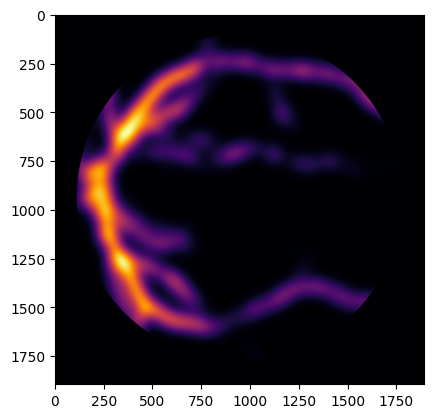

In [103]:
def get_vessel_map(img_bgr):
    w = img_bgr.shape[1]
    k_size = int(w * 0.02) | 1  # Must be odd
    green = img_bgr[:, :, 1]
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
    vessels = cv2.morphologyEx(green, cv2.MORPH_BLACKHAT, kernel)
    _, vessels_clean = cv2.threshold(vessels, 15, 255, cv2.THRESH_BINARY)
    vessel_hub = cv2.GaussianBlur(vessels_clean.astype(np.float32), (251, 251), 0)
    return cv2.normalize(vessel_hub, None, 0, 1, cv2.NORM_MINMAX)

vessel_map = get_vessel_map(img_ori)
plt.imshow(vessel_map * fov_mask, cmap="inferno")

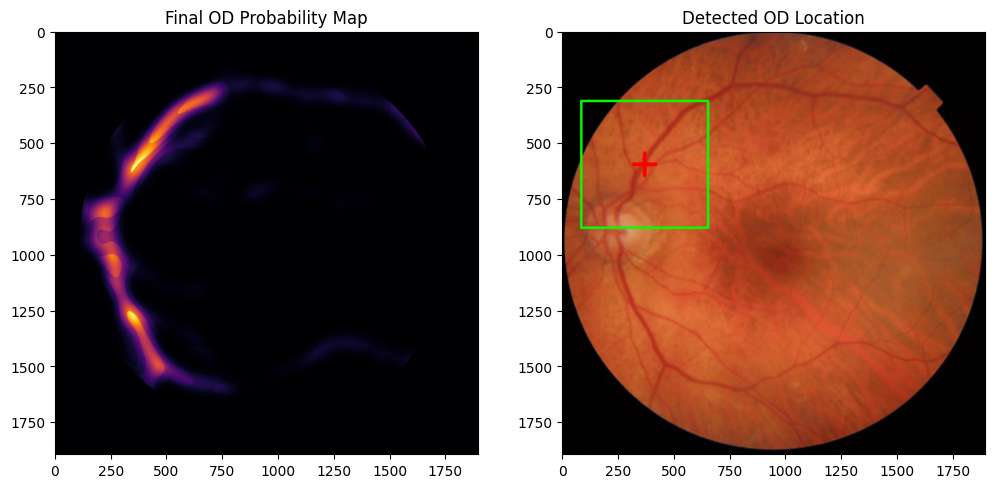

In [104]:
def find_od(map_ls: list):
    # FIND OVERLAPPING MAP
    combined_prob = None
    for map in map_ls:
        if combined_prob is None:
            combined_prob = map
        else:
            combined_prob *= map
    final_map = combined_prob**2

    # LOCATE THE PEAK
    final_map_8u = cv2.normalize(final_map, None, 0, 255, cv2.NORM_MINMAX).astype(
        np.uint8
    )
    _, _, _, max_loc = cv2.minMaxLoc(final_map_8u)
    return max_loc, final_map_8u


fov_mask = get_fov_mask(img_ori)
max_loc, final_map = find_od(
    map_ls=[
        fov_mask,
        texture_map,
        vessel_map,
    ],
)

# Visualize the final OD probability map and the detected location
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Final OD Probability Map")
plt.imshow(final_map, cmap="inferno")
plt.subplot(1, 2, 2)
img_marked = mark(img_ori, max_loc)
plt.title("Detected OD Location")
plt.imshow(cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB))

# OD Batch crop

In [105]:
class OD:
    def __init__(self, img):
        self.img = img
        # 1. Generate specialized maps
        self.fov_mask = self.get_fov_mask(self.img)
        self.texture_map = self.get_texture_map(self.img)
        self.vessel_map = self.get_vessel_map(self.img)

        # 2. Perform fusion and peak detection
        self.od_loc, self.heatmap = self.find_od(
            [self.fov_mask, self.texture_map, self.vessel_map]
        )

    @property
    def get_od_loc(self):
        return self.od_loc

    # ===== MAPPING FUNCTIONS =====
    def get_fov_mask(self, img_ori):
        """Generates a mask that suppresses the periphery (Halo Sieve)."""
        h, w = img_ori.shape[:2]
        green = img_ori[:, :, 1]
        blurred_fov = cv2.medianBlur(green, 31)

        # Hough Circle Detection for FOV
        circles = cv2.HoughCircles(
            blurred_fov,
            cv2.HOUGH_GRADIENT,
            dp=1.2,
            minDist=1000,
            param1=50,
            param2=30,
            minRadius=int(h * 0.3),
            maxRadius=int(h * 0.6),
        )

        fov_mask = np.zeros_like(green)
        if circles is not None:
            circles = np.uint16(np.around(circles))
            i = circles[0, 0]
            cv2.circle(fov_mask, (i[0], i[1]), i[2], 255, -1)
        else:
            _, fov_mask = cv2.threshold(blurred_fov, 10, 255, cv2.THRESH_BINARY)

        # Large erosion to kill crescent halos at the border
        kernel_erode = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (201, 201))
        halo_sieve = cv2.erode(fov_mask, kernel_erode, iterations=1)
        return halo_sieve.astype(np.float32) / 255.0

    def get_texture_map(self, img_ori):
        """Uses the Red channel to find high-density gradient hubs."""
        h, w = img_ori.shape[:2]
        red = img_ori[:, :, 2]  # Better contrast for OD rim
        red = cv2.medianBlur(red, 15)

        grad_red = cv2.morphologyEx(
            red,
            cv2.MORPH_GRADIENT,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
        )

        blur_tex = int(w * 0.15) | 1
        tex_hub = cv2.GaussianBlur(grad_red, (blur_tex, blur_tex), 0)

        return cv2.normalize(tex_hub, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)

    def get_vessel_map(self, img_bgr):
        """Detects the major vascular hub via sparse vessel extraction."""
        w = img_bgr.shape[1]
        k_size = int(w * 0.02) | 1
        green = img_bgr[:, :, 1]

        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
        vessels = cv2.morphologyEx(green, cv2.MORPH_BLACKHAT, kernel)

        # Threshold to keep only major vessels, removing background noise
        _, vessels_clean = cv2.threshold(vessels, 15, 255, cv2.THRESH_BINARY)
        vessel_hub = cv2.GaussianBlur(vessels_clean.astype(np.float32), (251, 251), 0)

        return cv2.normalize(vessel_hub, None, 0, 1, cv2.NORM_MINMAX)

    # ===== FUSION LOGIC =====

    def find_od(self, map_ls):
        """Fuses maps using logical multiplication and squares the result for peak clarity."""
        combined_prob = None
        for m in map_ls:
            if combined_prob is None:
                combined_prob = m
            else:
                combined_prob *= m

        # Squaring the map pushes 'weak' spots toward zero and 'sharpens' the peak
        final_map = combined_prob**2

        final_map_8u = cv2.normalize(final_map, None, 0, 255, cv2.NORM_MINMAX).astype(
            np.uint8
        )
        _, _, _, max_loc = cv2.minMaxLoc(final_map_8u)

        return max_loc, final_map_8u

    # ===== VISUALIZATION =====

    def plot(self):
        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        plt.title("Final OD Probability Map")
        plt.imshow(self.heatmap, cmap="inferno")
        plt.subplot(1, 2, 2)
        plt.title("Detected OD Location")
        plt.imshow(cv2.cvtColor(self.mark(), cv2.COLOR_BGR2RGB))
        plt.show()

    def mark(self, crop_ratio=0.3):
        out = self.img.copy()
        h, w = out.shape[:2]
        cv2.drawMarker(out, self.od_loc, (0, 0, 255), cv2.MARKER_CROSS, 100, 15)

        # Optional: Add a rectangle around the detection
        rw, rh = int(w * crop_ratio), int(h * crop_ratio)
        x1, y1 = max(self.od_loc[0] - rw // 2, 0), max(self.od_loc[1] - rh // 2, 0)
        x2, y2 = min(self.od_loc[0] + rw // 2, w), min(self.od_loc[1] + rh // 2, h)
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 10)
        return out

    def crop_od(self, crop_ratio=0.3, size=512):
        h, w = self.img.shape[:2]
        cw, ch = int(w * crop_ratio), int(h * crop_ratio)

        x1, y1 = max(self.od_loc[0] - cw // 2, 0), max(self.od_loc[1] - ch // 2, 0)
        x2, y2 = min(self.od_loc[0] + cw // 2, w), min(self.od_loc[1] + ch // 2, h)

        cropped = self.img[y1:y2, x1:x2]
        return cv2.resize(cropped, (size, size))

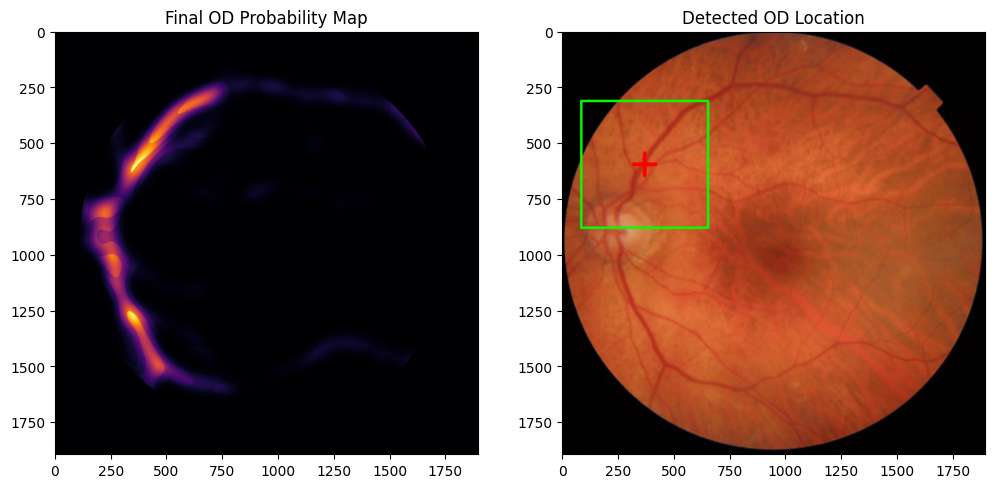

In [106]:
OD(img_ori).plot()

In [ ]:
path_processed_crop = here() / "data" / "processed" / "od"

df = pl.read_csv(path_processed / "labels.csv")
img_ls = df.select("Image Name").to_numpy().flatten().tolist()

loc_ls = []
for i in img_ls:
    current_img_path = path_raw_img / i
    current_img = cv2.imread(current_img_path)
    od = OD(current_img)
    cropped_od = od.crop_od()
    loc_ls.append(str(od.get_od_loc))
    cv2.imwrite(str(path_processed_crop / i), cropped_od)


df = df.with_columns(pl.Series("OD_loc", loc_ls))
df.write_csv(path_processed / "labels_od.csv")